In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from returns import load_log_returns

In [70]:
returns = load_log_returns("historical_data/market_15_assets_10y.csv")

In [71]:
# 1. First, I analyze the matrix shape, for easier analysis i need shape (t_days, n_assets)

returns.shape

(2513, 15)

In [72]:
R = (returns - returns.mean(axis=0)) / returns.std(axis=0, ddof=1)

In [77]:
# 2. The fundament of structural analysis is Singular Value Decomposition SVD

# U contains information about pattern activity over time (how much pattern was 'switch on' during a day
# S gives information about the strength of each pattern, sorted from biggest to smallest
# Vt containts information about patters across stocks

U, S, Vt = np.linalg.svd(R, full_matrices=False)

In [74]:
# k - number of directions
k_list = list(np.arange(1, 16))
variances_over_k = []

for k in k_list:
    S_k = S[:k]
    variance_over_k = float(np.sum(S_k ** 2) / np.sum(S ** 2))
    variances_over_k.append(variance_over_k)
print(variances_over_k)

[0.3361891561192305, 0.46148856737317834, 0.5731348562573075, 0.6655445393926128, 0.7212183552923549, 0.7734050074616657, 0.8076134766048917, 0.8409823991536081, 0.8708283427514725, 0.8983820621319005, 0.9224551467147506, 0.9450199202780378, 0.9669804431900884, 0.9872472531650299, 1.0]


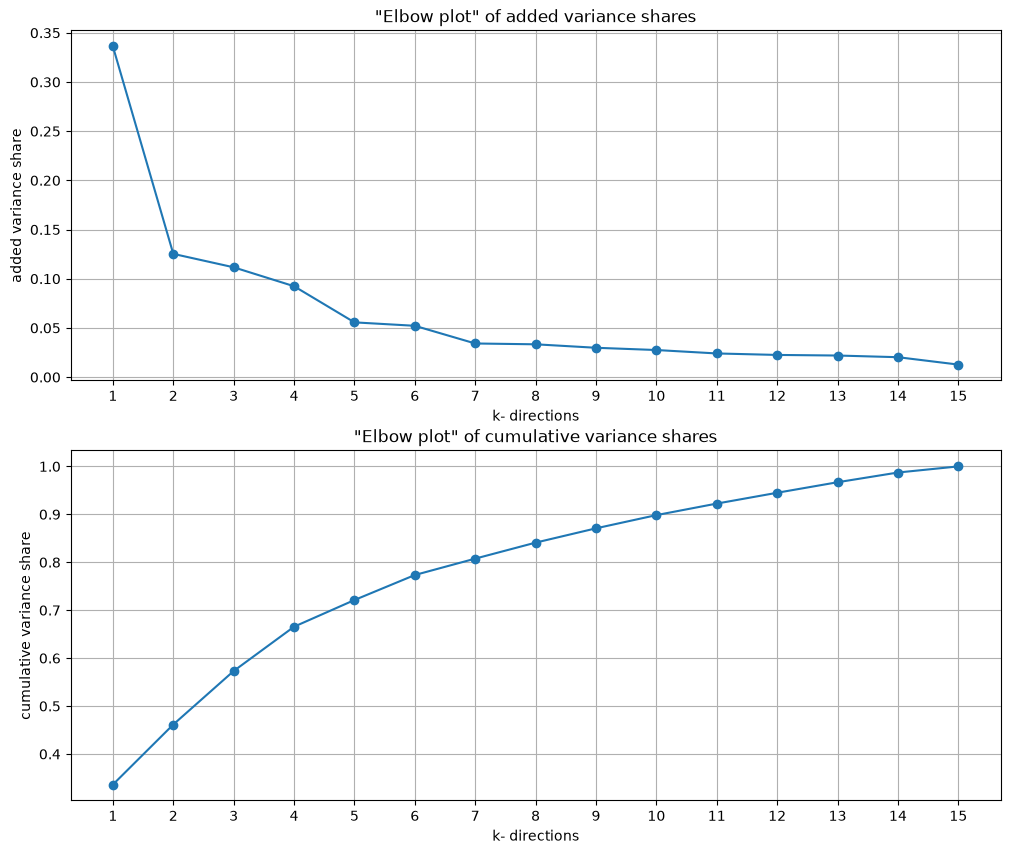

In [75]:
added_variances = np.zeros(len(variances_over_k))
added_variances[0] = variances_over_k[0]
ks = np.arange(1, len(variances_over_k) + 1)

for i in range(1, 15):
    added_variances[i] = variances_over_k[i] - variances_over_k[i-1]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

ax1.plot(ks, added_variances, marker='o')
ax1.grid(True)
ax1.set_title('"Elbow plot" of added variance shares')
ax1.set_xlabel('k- directions')
ax1.set_ylabel('added variance share')

ax2.plot(ks, variances_over_k, marker='o')
ax2.grid(True)
ax2.set_title('"Elbow plot" of cumulative variance shares')
ax2.set_xlabel('k- directions')
ax2.set_ylabel('cumulative variance share')

for ax in (ax1, ax2):
    ax.set_xticks(ks)

plt.show()

In [76]:
# Cutoff choice: k = 4.
# The added variance falls sharply after PC1 (33.6% -> 12.5%) and again after PC4
# (9.2% -> 5.5%); PC5 and PC6 form a flat plateau (~5%), typical of the noise floor.
# Cutting after PC1 would keep only the market factor, so I keep PC1-PC4, i.e. all
# components before the lower plateau.

In [79]:
# 2. Reconstructed
U_k, S_k, Vt_k = U[:, :k], np.diag(S[:k]), Vt[:k, :]
reconstructed = U_k @ S_k @ Vt_k

In [82]:
# 3, Most extreme day
directions = reconstructed @ Vt_k.T
center = np.mean(directions, axis=0)
distances = directions - center
dist = np.linalg.norm(distances, axis=1)
most_extreme_day = np.argmax(dist)

print(most_extreme_day)

851
